In [ ]:
#Demo code for horizontal and vertical edge kernels

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from PIL import Image
from scipy.signal import convolve2d

In [ ]:
def detect_edges(image_path):
  img = Image.open(image_path).convert("L")
  img_array = np.array(img)

  horizontal_kernel = np.array([[-1, -1, -1],
                                [0,0,0],
                                [1,1,1]])

  vertical_kernel = np.array([[-1, 0, 1],
                              [-1, 0, 1],
                              [-1, 0, 1]])

  horizontal_edges = convolve2d(img_array, horizontal_kernel, mode='same',boundary='symm')
  vertical_edges = convolve2d(img_array, vertical_kernel, mode='same',boundary='symm')
  horizontal_edges = (horizontal_edges - horizontal_edges.min()) / (horizontal_edges.max() - horizontal_edges.min())
  vertical_edges = (vertical_edges - vertical_edges.min()) / (vertical_edges.max() - vertical_edges.min())

  return img_array, horizontal_edges, vertical_edges

In [ ]:
# from google.colab import files
# files.upload()

In [ ]:
#implement CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

In [ ]:
(train_images, train_labels),(test_images, test_labels) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
train_images[8]
#0-255.   0-1

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   5,
         63, 197,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  20,
        254, 230,  24,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  20,
        254, 254,  48,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  20,
        254, 255,  48,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  20,
        254, 254,  57,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  20,
        254, 254, 108,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  16,
        239, 254, 143,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        178, 254, 143,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        178, 254, 143,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        178, 254, 162,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        178, 254, 240,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        113, 254, 240,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         83, 254, 245,  31,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         79, 254, 246,  38,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 214, 254, 150,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 144, 241,   8,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 144, 240,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 144, 254,  82,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 230, 247,  40,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   

In [ ]:
#normalized the pixes range initially -0-255 is 0-1
train_images = train_images.astype('float32')/255
test_images = test_images.astype('float32')/255

In [ ]:
train_images[8]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

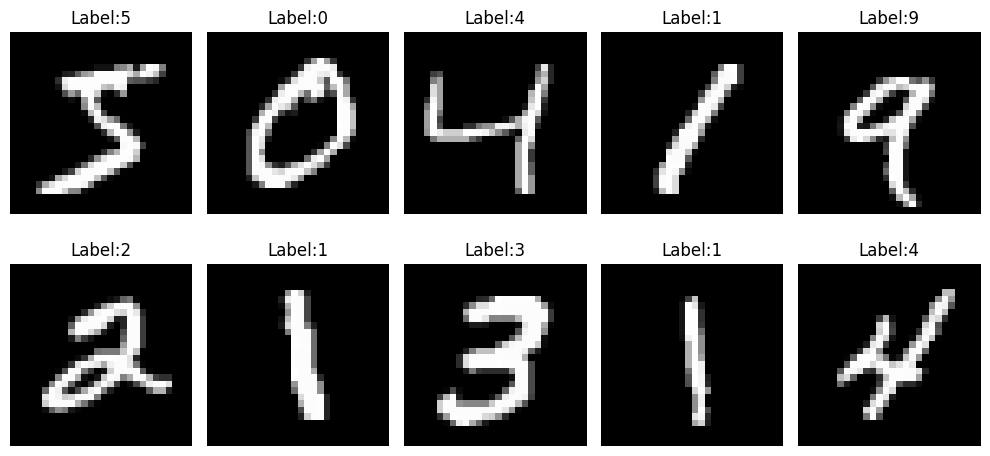

In [ ]:
plt.figure(figsize=(10,5))
for i in range(10):
  plt.subplot(2,5, i+1)
  img = train_images[i]
  plt.imshow(img, cmap='gray')
  plt.title(f"Label:{train_labels[i]}")
  plt.axis('off')
plt.tight_layout()

In [ ]:
# image - one, 3  all tehe data -1, 28,28,1 -> image - 28.28,2
train_images = train_images.reshape((-1, 28, 28, 1))
test_images = test_images.reshape((-1, 28, 28, 1))

In [ ]:
#one hot encoding
train_labels = tf.keras.utils.to_categorical(train_labels)
test_labels = tf.keras.utils.to_categorical(test_labels)

In [ ]:
train_labels[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [ ]:
#random - model you fix this -> hyperparamerter tuning
def create_model():
  model = models.Sequential([
      data_augmentation,
      #cnn
      layers.Conv2D(32, (3,3), activation='relu',
                    input_shape=(28,28,1)),
      layers.BatchNormalization(), #this layer is a must
      layers.MaxPooling2D((2,2)),

      layers.Conv2D(64, (3,3), activation='relu'),
      layers.BatchNormalization(), #this layer is a must
      layers.MaxPooling2D((2,2)),

      layers.Conv2D(64, (3,3), activation='relu'),
      layers.BatchNormalization(),  #last layer of cnn
       #flatten
      layers.Flatten(),
      #ANN
      layers.Dense(128,activation='relu'),
      layers.Dropout(0.5),
      layers.Dense(10,activation='softmax')])
  return model

In [ ]:
model = create_model()
model.compile(optimizer='adam',
              loss = "categorical_crossentropy",
              metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
early_stopping = callbacks.EarlyStopping(patience=5,
                                         restore_best_weights=True)

reduce_lr = callbacks.ReduceLROnPlateau(factor=0.20, patience=3)

In [ ]:
history = model.fit(train_images, train_labels,
                    epochs=30,
                    batch_size=128,
                    validation_split=0.1,
                    callbacks=[early_stopping,reduce_lr])

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.8122 - loss: 0.6074 - val_accuracy: 0.9535 - val_loss: 0.1898 - learning_rate: 0.0010
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9636 - loss: 0.1239 - val_accuracy: 0.9852 - val_loss: 0.0506 - learning_rate: 0.0010
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9702 - loss: 0.0998 - val_accuracy: 0.9867 - val_loss: 0.0492 - learning_rate: 0.0010
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9756 - loss: 0.0821 - val_accuracy: 0.9863 - val_loss: 0.0487 - learning_rate: 0.0010
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9784 - loss: 0.0742 - val_accuracy: 0.9870 - val_loss: 0.0500 - learning_rate: 0.0010
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9819 - loss: 0.0629 - val_accuracy: 0.9908 - val_loss: 0.0355 - learning_rate: 0.0010
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9835 - loss: 0

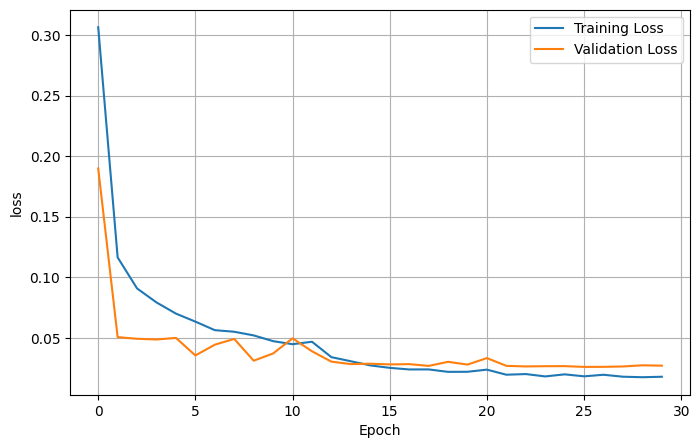

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.grid()
plt.legend()

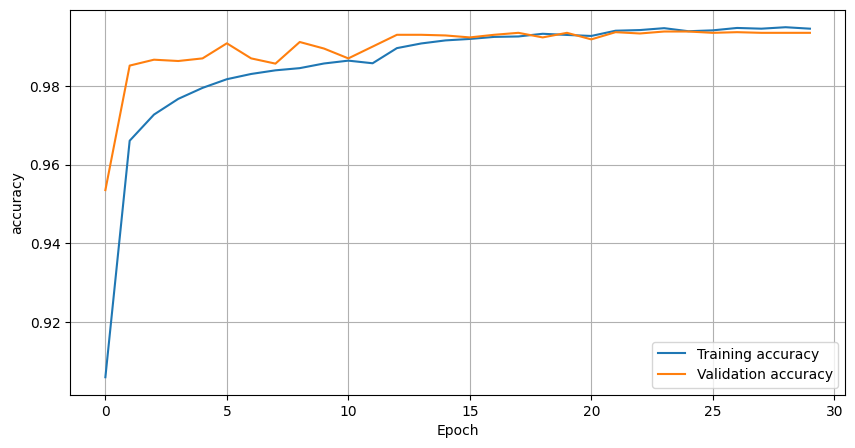

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Validation accuracy')
plt.xlabel("Epoch")
plt.ylabel("accuracy")
plt.grid()
plt.legend()

In [ ]:
model.save('mnist_cnn_model.keras')

In [ ]:
def predict_image(image_path,model):
  img = Image.open(image_path).convert('L')
  img = ImageOps.invert(img)
  img = img.resize((28,28))
  img_array = np.array(img)
  img_array = img_array.astype('float32')/255
  img_array = img_array.reshape((1,28,28,1))

  prediction = model.predict(img_array)
  print(f"prediction : {prediction}")
  predicted_class = np.argmax(prediction)
  confidence = np.max(prediction)
  return predicted_class, confidence

In [ ]:
def load_model_and_predict(image_path):
  loaded_model = tf.keras.models.load_model('mnist_cnn_model.keras')
  predicted_class, confidence = predict_image(image_path,loaded_model)
  print(f"Predicted Class : {predicted_class}")
  print(f"Confidence : {confidence}")

  img = Image.open(image_path).convert("L")
  plt.imshow(img, cmap='gray')
  plt.title(f"PREDICTED : {predicted_class} (Confidence : {confidence:.2f})")
  plt.axis('off')

In [ ]:
# from google.colab import files
# files.upload()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
prediction : [[2.40417634e-04 1.05054778e-05 4.64524888e-03 1.62280514e-04
  2.60366709e-03 8.43395756e-05 9.70707879e-06 1.16524556e-04
  9.91743743e-01 3.83510167e-04]]
Predicted Class : 8
Confidence : 0.9917437434196472


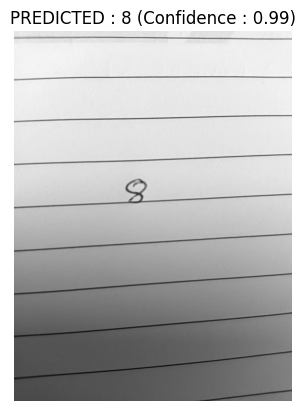

In [ ]:
image_path = "/content/IMG20240820192035.jpg"
load_model_and_predict(image_path)